In [15]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt



In [2]:
from sklearn.datasets import fetch_california_housing 
housing = fetch_california_housing() 
print(housing.data.shape, housing.target.shape)



(20640, 8) (20640,)


In [3]:
#Convert features into a pandas DataFrame
df = pd.DataFrame(data=housing.data, columns=housing.feature_names)
df['MedHouseVal'] = housing.target  #  add the trget value 
df


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422
...,...,...,...,...,...,...,...,...,...
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09,0.781
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21,0.771
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22,0.923
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32,0.847


In [8]:

display(df.sample(5))

# Column names
print(df.columns.tolist())

# Dataset dimensions
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# Data types
print(df.dtypes)

# Dataset information
df.info()

# Dataset description
print(housing.DESCR)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
7548,3.1538,39.0,5.072464,1.048309,895.0,4.323671,33.92,-118.20,1.556
15011,2.7340,26.0,4.220792,1.026733,2199.0,2.177228,32.77,-117.04,1.489
8295,4.0795,39.0,3.518519,1.118166,867.0,1.529101,33.75,-118.14,4.000
20003,1.9091,29.0,5.353982,1.109145,1421.0,4.191740,36.06,-119.19,0.713
13820,5.1112,4.0,7.366460,1.121118,1017.0,3.158385,34.49,-117.25,1.709


['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']
Rows: 20640
Columns: 9
MedInc         float64
HouseAge       float64
AveRooms       float64
AveBedrms      float64
Population     float64
AveOccup       float64
Latitude       float64
Longitude      float64
MedHouseVal    float64
dtype: object
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB
.. _california_housing_dataset:

California

In [10]:
# Unique values
print("Unique values:")
display(df.nunique())

# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Unique values:


MedInc         12928
HouseAge          52
AveRooms       19392
AveBedrms      14233
Population      3888
AveOccup       18841
Latitude         862
Longitude        844
MedHouseVal     3842
dtype: int64

Duplicate rows: 0


In [20]:
# Skewness
print("Skewness:")
display(df.skew().sort_values(ascending=False))

Skewness:


AveOccup       97.639561
AveBedrms      31.316956
AveRooms       20.697869
Population      4.935858
MedInc          1.646657
MedHouseVal     0.977763
Latitude        0.465953
HouseAge        0.060331
Longitude      -0.297801
dtype: float64

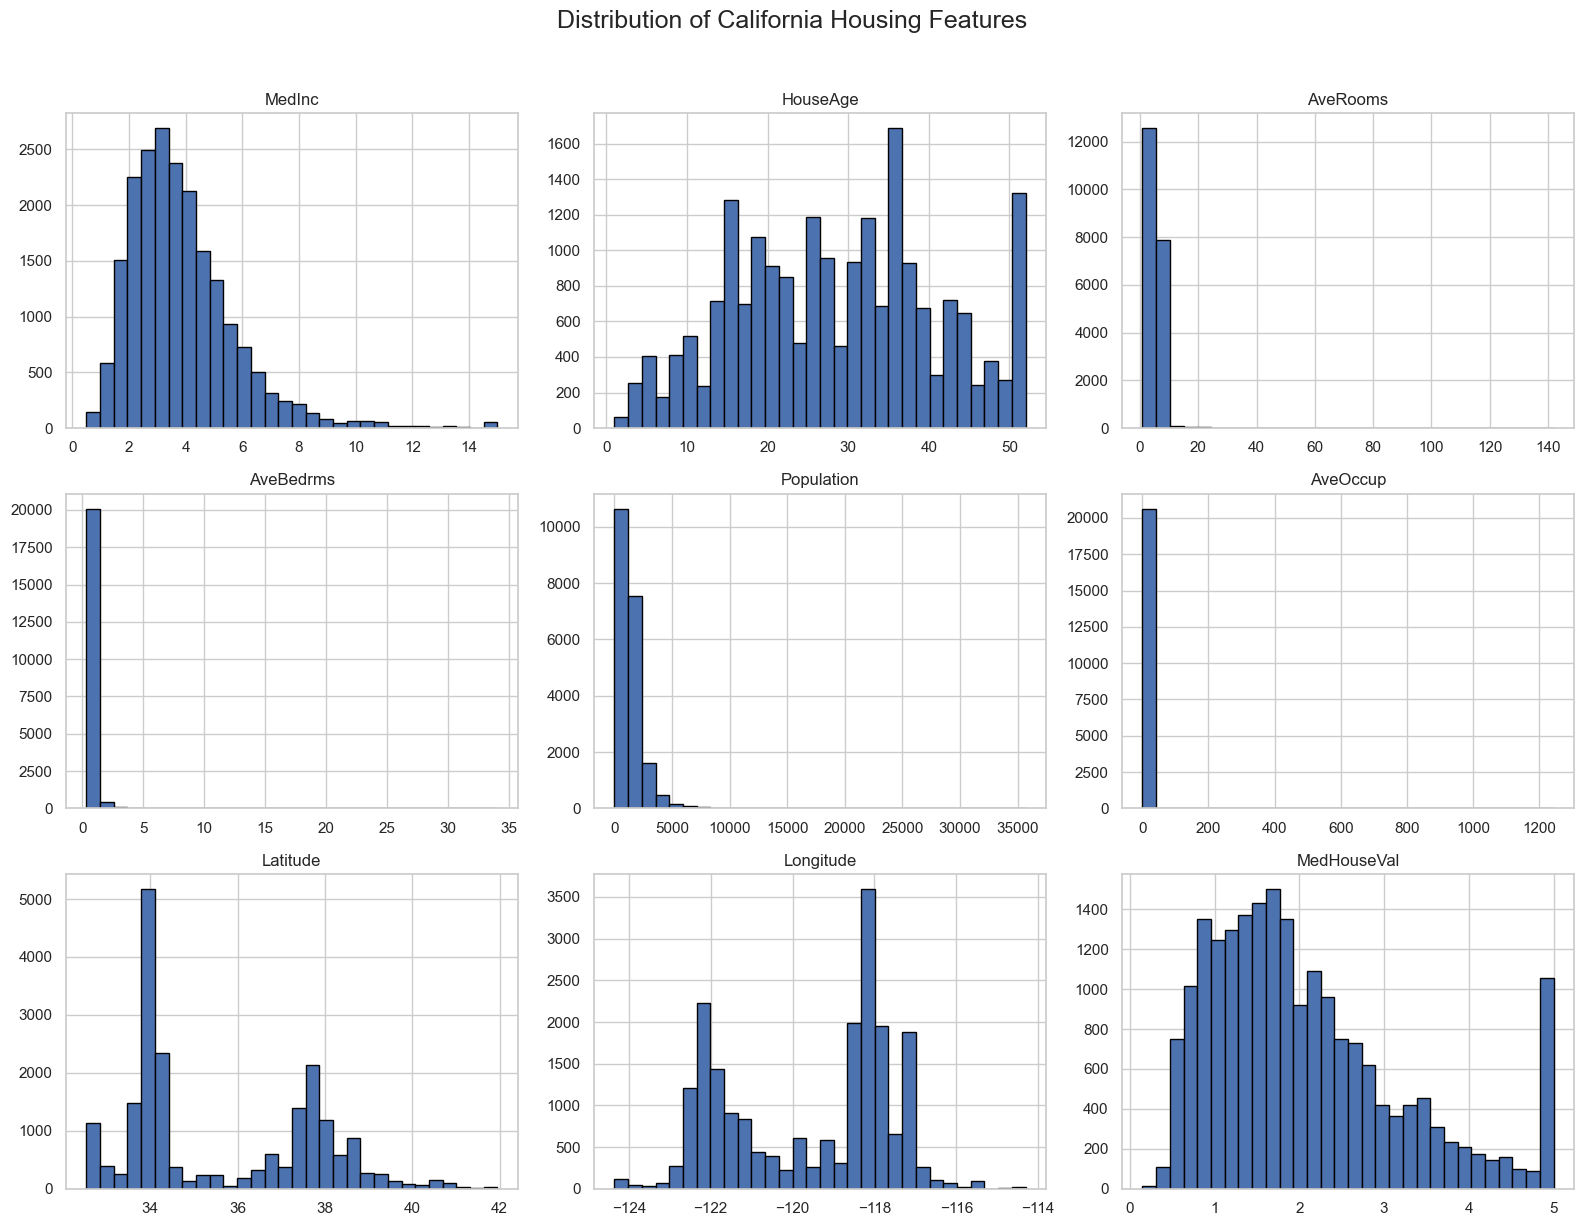

In [16]:
sns.set_theme(style="whitegrid")

df.hist(
    figsize=(16, 12),
    bins=30,
    edgecolor="black"
)

plt.suptitle(
    "Distribution of California Housing Features",
    fontsize=18,
    y=1.02
)

plt.tight_layout()
plt.show()

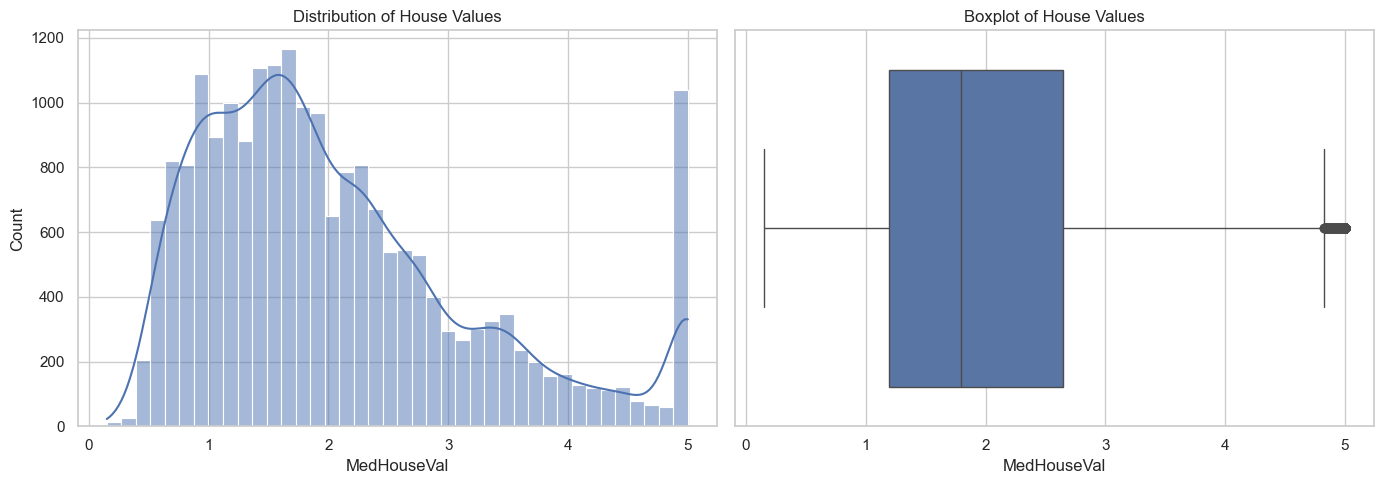

Target mean: 2.0685581690891475
Target median: 1.797
Target minimum: 0.14999
Target maximum: 5.00001


In [17]:
# target value analysis
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    df["MedHouseVal"],
    bins=40,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Distribution of House Values")

sns.boxplot(
    x=df["MedHouseVal"],
    ax=axes[1]
)
axes[1].set_title("Boxplot of House Values")

plt.tight_layout()
plt.show()

print("Target mean:", df["MedHouseVal"].mean())
print("Target median:", df["MedHouseVal"].median())
print("Target minimum:", df["MedHouseVal"].min())
print("Target maximum:", df["MedHouseVal"].max())

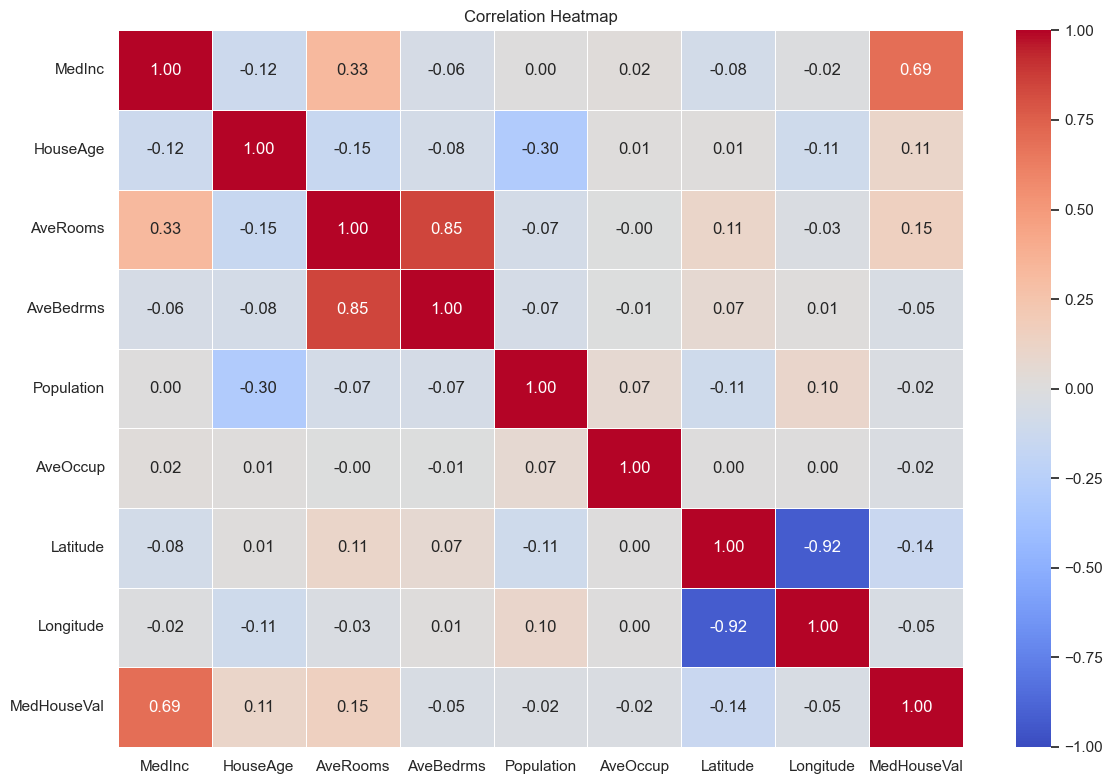

,Correlation with House Value
MedInc,0.688075
AveRooms,0.151948
HouseAge,0.105623
AveOccup,-0.023737
Population,-0.024650
Longitude,-0.045967
AveBedrms,-0.046701
Latitude,-0.144160


In [18]:
#Correlation analysis
corr = df.corr(numeric_only=True)

plt.figure(figsize=(12, 8))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

# Correlation with target
target_corr = corr["MedHouseVal"].drop("MedHouseVal")

display(
    target_corr
    .sort_values(ascending=False)
    .to_frame("Correlation with House Value")
)

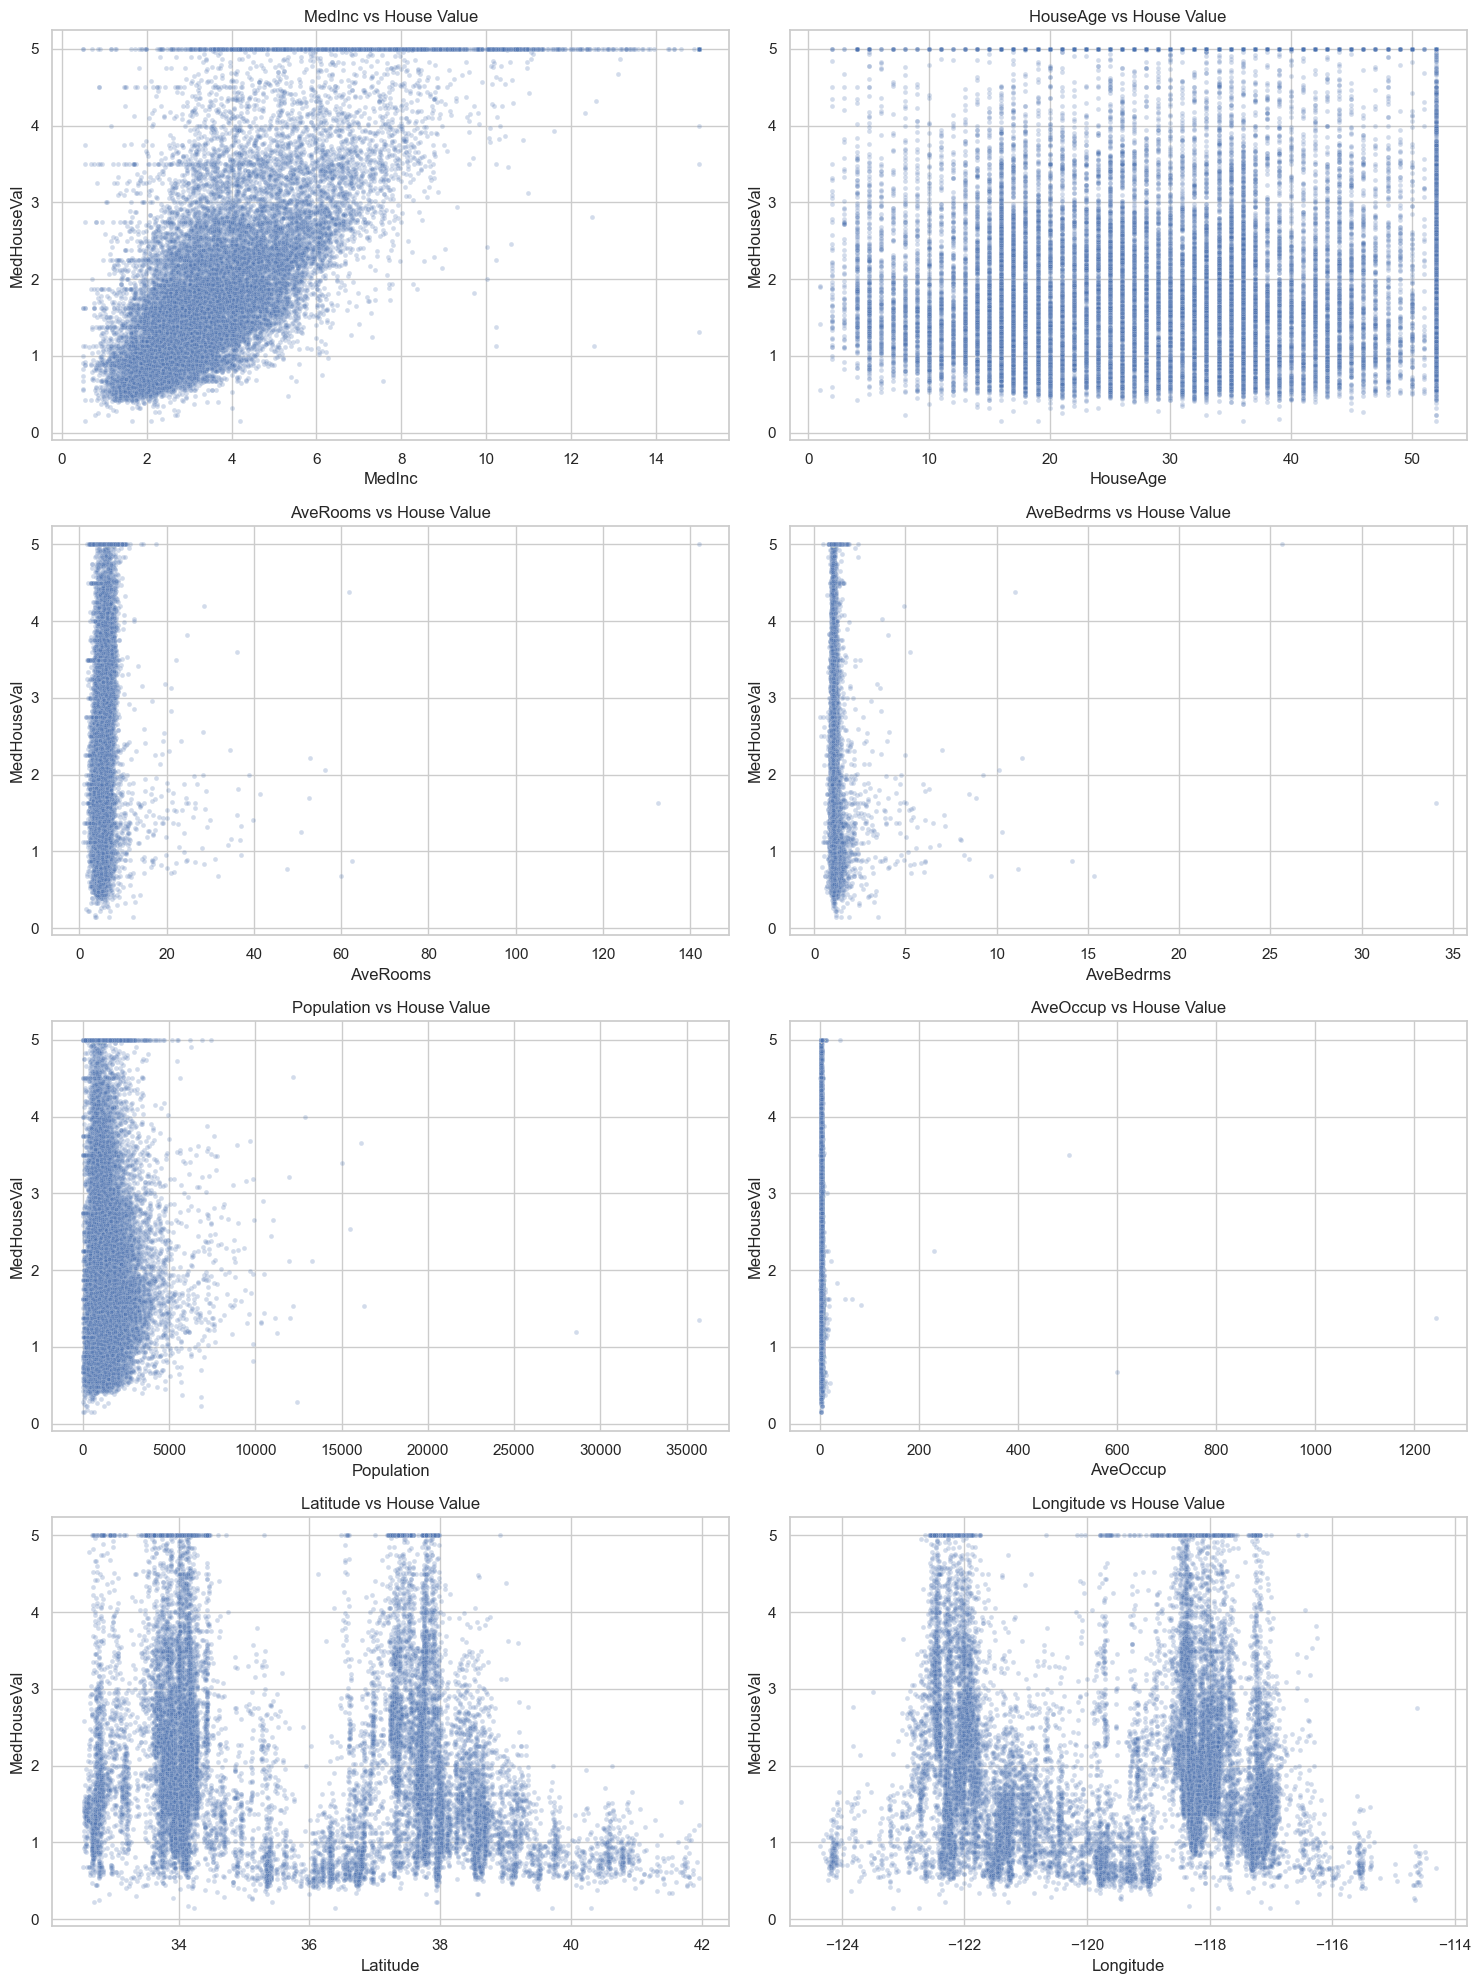

In [19]:
#Feature vs. target visualization
features = [
    "MedInc",
    "HouseAge",
    "AveRooms",
    "AveBedrms",
    "Population",
    "AveOccup",
    "Latitude",
    "Longitude"
]

fig, axes = plt.subplots(4, 2, figsize=(15, 20))

for feature, ax in zip(features, axes.flatten()):
    sns.scatterplot(
        data=df,
        x=feature,
        y="MedHouseVal",
        alpha=0.25,
        s=12,
        ax=ax
    )

    ax.set_title(f"{feature} vs House Value")

plt.tight_layout()
plt.show()

In [41]:
X = df.drop('MedHouseVal', axis=1)

y=df['MedHouseVal']




In [42]:
X.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


In [51]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

In [52]:
# Feature Scaling (Normalizes data so features like Population don't dominate Income)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [69]:
model = RandomForestRegressor(n_estimators=300, random_state=42)
model.fit(X_train_scaled, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [70]:
y_pred=model.predict(X_test_scaled)

In [71]:
from sklearn.metrics import r2_score
r2=r2_score(y_test, y_pred)
print("r_sqaure:", r2)

r_sqaure: 0.8064352138155145


# LightGBM/XGBoost

In [68]:
from sklearn.ensemble import HistGradientBoostingRegressor

# Yeh bilkul LightGBM/XGBoost ki tarah fast aur accurate hai, bina install kiye chalega
hgb_model = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, max_depth=6, random_state=42)
hgb_model.fit(X_train_scaled, y_train)

y_pred = hgb_model.score(X_test_scaled,  y_test)
y_pred

0.8352111265269868